# Notebook 12 — U-Net Ablation Study

**Project:** Next Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Owners:** Riya and Tejas  
**Phase:** 2 (Deep Learning)  
**Objective:** Change one thing at a time and measure how much each design choice matters, using validation PR-AUC only (the test set stays untouched).

---

## 1. Setup
Training the full U-Net takes about 30 minutes, so every ablation run uses the **same smaller budget**: the first 4,000 training maps, up to 10 epochs, patience 3. All runs share the same seed, so the only difference between rows is the one thing we changed. Scores are on the full validation set, never on test.

In [1]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

import src.dl_data as dd
import src.dl_model as dm

data_dir = "data/processed/dl"
norm = dict(np.load("results/models/unet_norm.npz"))
train_X, train_Y = dd.load_split(data_dir, "train", 4000)
val_X, val_Y = dd.load_split(data_dir, "eval")
train_X = dd.normalize(train_X, norm)
val_X = dd.normalize(val_X, norm)
val_mask = val_Y >= 0
print("train maps:", len(train_X), "validation maps:", len(val_X))


train maps: 4000 validation maps: 1877


## 2. The experiments

In [2]:
weather = ["vs", "wind_x", "wind_y", "tmmn", "tmmx", "sph", "pr"]
experiments = [
    ("Full U-Net (reference)", {}),
    ("No augmentation", {"augment": False}),
    ("Flips without wind fix", {"fix_wind": False}),
    ("No fire class weight", {"pos_weight": 1.0}),
    ("Focal loss instead of weighted BCE", {"loss": "focal", "pos_weight": 1.0}),
    ("Without fire today (PrevFireMask)", {"drop_channels": ["PrevFireMask"]}),
    ("Without weather channels", {"drop_channels": weather}),
]

rows = []
for name, change in experiments:
    start = time.time()
    model, history = dm.train_unet(train_X, train_Y, val_X, val_Y, epochs=10, patience=3, verbose=0, **change)
    prob = dm.predict_maps(model, val_X, change.get("drop_channels"))
    score = average_precision_score(val_Y[val_mask], prob[val_mask])
    rows.append({"experiment": name, "val_pr_auc": round(score, 4), "epochs_run": len(history["loss"]),
                 "minutes": round((time.time() - start) / 60, 1)})
    print(rows[-1])

ablation = pd.DataFrame(rows)
reference = ablation.loc[0, "val_pr_auc"]
ablation["change_vs_reference"] = (ablation["val_pr_auc"] - reference).round(4)
ablation.to_csv("results/metrics/dl_ablation_results.csv", index=False)
ablation


{'experiment': 'Full U-Net (reference)', 'val_pr_auc': 0.2595, 'epochs_run': 10, 'minutes': 5.1}


{'experiment': 'No augmentation', 'val_pr_auc': 0.2365, 'epochs_run': 10, 'minutes': 5.3}


{'experiment': 'Flips without wind fix', 'val_pr_auc': 0.2553, 'epochs_run': 10, 'minutes': 4.8}


{'experiment': 'No fire class weight', 'val_pr_auc': 0.2333, 'epochs_run': 10, 'minutes': 4.9}


{'experiment': 'Focal loss instead of weighted BCE', 'val_pr_auc': 0.2314, 'epochs_run': 10, 'minutes': 5.0}


{'experiment': 'Without fire today (PrevFireMask)', 'val_pr_auc': 0.1754, 'epochs_run': 10, 'minutes': 231.3}


{'experiment': 'Without weather channels', 'val_pr_auc': 0.2429, 'epochs_run': 10, 'minutes': 4.6}


,experiment,val_pr_auc,epochs_run,minutes,change_vs_reference
0,Full U-Net (reference),0.2595,10,5.1,0.0000
1,No augmentation,0.2365,10,5.3,-0.0230
2,Flips without wind fix,0.2553,10,4.8,-0.0042
3,No fire class weight,0.2333,10,4.9,-0.0262
4,Focal loss instead of weighted BCE,0.2314,10,5.0,-0.0281
5,Without fire today (PrevFireMask),0.1754,10,231.3,-0.0841
6,Without weather channels,0.2429,10,4.6,-0.0166


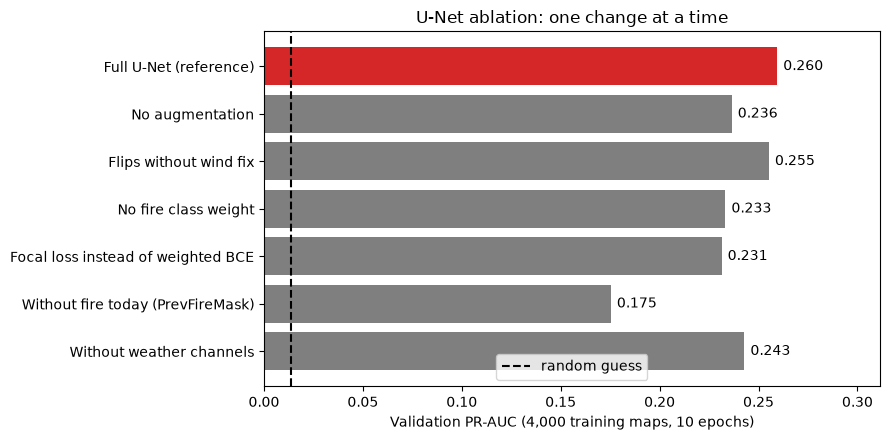

In [3]:
plot_df = ablation.iloc[::-1]
colors = ["tab:red" if e == "Full U-Net (reference)" else "tab:gray" for e in plot_df["experiment"]]

plt.figure(figsize=(9, 4.5))
bars = plt.barh(plot_df["experiment"], plot_df["val_pr_auc"], color=colors)
for b, v in zip(bars, plot_df["val_pr_auc"]):
    plt.text(v + 0.003, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
plt.axvline(val_Y[val_mask].mean(), color="black", linestyle="--", label="random guess")
plt.xlabel("Validation PR-AUC (4,000 training maps, 10 epochs)")
plt.title("U-Net ablation: one change at a time")
plt.xlim(0, plot_df["val_pr_auc"].max() * 1.2)
plt.legend()
plt.tight_layout()
plt.savefig("results/figures/dl_ablation.png", dpi=150)
plt.show()


## 3. Summary
- **Fire today (`PrevFireMask`) matters most:** removing it drops PR-AUC by 0.084, from 0.260 to 0.175. It is still above random because the maps are centred on fires, so the other channels still hint where the fire is.
- **Loss choice:** weighting fire pixels 3 times beats plain BCE (−0.026) and focal loss (−0.028).
- **Augmentation helps:** without flips PR-AUC drops by 0.023.
- **Weather helps a little:** without wind, temperature, humidity and rain PR-AUC drops by 0.017.
- **Wind fix:** flipping without fixing the wind is only slightly worse (−0.004). That is too small to call a real effect with one seed, but fixing the wind is still the correct thing to do.
- These runs use a smaller budget (4,000 maps, 10 epochs), so the reference is 0.260 instead of the full model's 0.298. The ranking of the changes is what matters.
- The `minutes` column for "Without fire today" is 231 because the laptop went to sleep during that run. Its result is not affected.